# 06 — Case study: EDNN total-uncertainty maps, 3 February 2022, 1800 UTC

Spatial maps of the EDNN total predictive uncertainty for every configuration that uses EDNN, at the case-study time, for forecast **days 1, 3 and 7**. This is the companion to notebook 05 (ptype maps) and replaces the original manuscript uncertainty figure.

**Systems (6):** Aurora, GraphCast, WXFormer, FuXi and Pangu-Weather (ERA5-initialized), and GFS, all with EDNN.

**Processing**
1. Valid time **1800 UTC 3 February 2022**. For each forecast day, the init time and lead follow the notebook-01 rule (00Z init; day *n* covers leads 24(n−1)+6 … 24n h): day 1 = 3 Feb 00Z + 18 h, day 3 = 1 Feb 00Z + 66 h, day 7 = 28 Jan 00Z + 162 h.
2. **Total uncertainty** $U_{tot} = \sum_k \mathrm{ale}_k + \sum_k \mathrm{epi}_k$ over the four classes (`ML_*_ale`, `ML_*_epi`), the same definition as the seasonal uncertainty figures.
3. Nearest-neighbour regridding onto a common 0.25° CONUS grid (same grid as notebook 05).
4. **CONUS mask:** ocean, Great Lakes, Canada and Mexico removed.
5. **GFS precipitation mask:** points where native GFS diagnoses no ptype (−1) in the **same forecast day** are removed from every panel. Display only.

**Outputs** (in `OUT` and `FIG`)

| File | Contents |
|---|---|
| `case_study_total_uncertainty_<time>_day<d>.pdf` | 2 × 3 map figure for each forecast day |
| `case_study_total_uncertainty_<time>_days.pdf` | Combined figure: rows = days, columns = systems |
| `case_study_total_uncertainty_stats_<time>.csv` | Median, 90th percentile, max and exceedance fractions of the displayed values |

> Run with **Kernel → Restart & Run All**. Use the same `MODEL_DIRS`, `FILE_GLOBS` and `PTYPE_VAR` as your working copy of notebook 05.

## 1. Imports

In [1]:
from pathlib import Path
import glob, re, warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from scipy.spatial import cKDTree
import shapely
from shapely.geometry import box
from shapely.ops import unary_union
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader

pd.set_option("display.max_columns", 100)

/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 2. Configuration

**Copy from your notebook 05:** `MODEL_DIRS`, `FILE_GLOBS` and `PTYPE_VAR["Native"]`. Only `au_ptype` is known here; the other directory names are placeholders.

- `UNC_DAYS`: forecast days to map.
- `UNC_VMAX`: upper end of the linear colour scale (the colourbar is extended if values exceed it).
- `OVERLAY_MPING_MIXED`: draw the mPING ice pellet and freezing rain reports at `VALID` on every panel.

In [12]:
# ============================================================
# PATHS (same as notebooks 01–05)
# ============================================================
OBS_RULE = "modal"
_RULE_SUFFIX = "" if OBS_RULE == "consensus" else f"_{OBS_RULE}"
MPING_PATH = "/glade/campaign/cisl/aiml/ai2es/winter_ptypes/ptype_qc/mPING_hourafter_interpolated_QC3.parquet"
AI_BASE = Path("/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE")
OUT = AI_BASE / f"verification_multimodel{_RULE_SUFFIX}"
FIG = Path("/glade/work/sakor/AI_NWP") / f"figures{_RULE_SUFFIX}"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# ============================================================
# CASE
# ============================================================
VALID = pd.Timestamp("2022-02-03 18:00")
UNC_DAYS = [1, 3, 7]

# ============================================================
# FORECAST FILES AND VARIABLES  (copy from notebook 05)
# ============================================================
MODELS = ["Aurora", "GraphCast", "WXFormer", "FuXi", "Pangu-Weather", "GFS"]
MODEL_DIRS = {
    "Aurora": AI_BASE / "au_ptype",
    "GraphCast": AI_BASE / "gc_ptype",
    "Pangu-Weather": AI_BASE / "pw_ptype",
    "WXFormer": AI_BASE / "wx_ptype",
    "FuXi": AI_BASE / "fuxi_ptype",
    "GFS": Path("/glade/derecho/scratch/sakor/gfs/processed"),
}
FILE_GLOBS = [                          # tried in order; the first unique match wins
    "{init:%Y-%m-%dT%H}Z/*_{lead:03d}.nc",      # e.g. 2022-02-03T00Z/aurora_2022-02-03T00Z_018.nc
    "{init:%Y-%m-%dT%H}Z/*_{lead}.nc",
    "{init:%Y%m%d%H}/*_{lead}.nc",
    "{init:%Y%m%d%H}/*_{lead:03d}.nc",
    "*{init:%Y%m%d%H}*_{lead}.nc",
    "*{init:%Y%m%d%H}*_{lead:03d}.nc",
]
PTYPE_VAR = {"Native": None}                  # GFS native ptype variable; None = auto-detect
NATIVE_PATTERNS = [r"^ptype_gfs$", r"gfs.*ptype|ptype.*gfs", r"native", r"^ptype$"]
ALE_RE = re.compile(r"^ML_(rain|snow|icep|frzr)_ale$")
EPI_RE = re.compile(r"^ML_(rain|snow|icep|frzr)_epi$")

# ============================================================
# GRID, MASKS, MAP (same as notebook 05)
# ============================================================
GRID_RES = 0.25
LAT_T = np.arange(20.0, 55.0 + 1e-9, GRID_RES)
LON_T = np.arange(-130.0, -60.0 + 1e-9, GRID_RES)
MAX_REGRID_KM = 60.0
CONUS_SHAPEFILE = None                        # None = Natural Earth states (Great Lakes excluded)
CONUS_BOX = box(-128.0, 22.0, -64.0, 51.0)
MAP_EXTENT = [-120.0, -73.0, 23.0, 50.0]
PROJ = ccrs.LambertConformal(central_longitude=-96, central_latitude=39,
                             standard_parallels=(33, 45))
DRAW_STATES = True

# ============================================================
# UNCERTAINTY DISPLAY
# ============================================================
UNC_VMAX = 0.75
UNC_CMAP = ListedColormap(plt.get_cmap("Oranges")(np.linspace(0.08, 1.0, 256)))
UNC_CMAP.set_bad("white")
OVERLAY_MPING_MIXED = False
MIXED_STYLE = {"Ice Pellet": ("o", "#CC79A7"), "Freezing Rain": ("^", "#2b2b2b")}

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 7.5,
    "axes.titlesize": 8, "axes.labelsize": 7.5,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
LETTERS = "abcdefghijklmnopqrstuvwxyz"
TIME_TAG = f"{VALID:%Y%m%d_%H}z"
EDNN_SYSTEMS = [f"{m} — EDNN" for m in MODELS]

## 3. Helpers: file lookup, reading and regridding

In [7]:
def init_and_lead(valid, day):
    init = (valid - pd.Timedelta(hours=1)).floor("D") - pd.Timedelta(days=day - 1)
    lead = int((valid - init) / pd.Timedelta(hours=1))
    assert 24 * (day - 1) + 6 <= lead <= 24 * day, (init, lead)
    return init, lead

def forecast_file(model, init, lead):
    tried = []
    for pat in FILE_GLOBS:
        p = str(MODEL_DIRS[model] / pat.format(init=init, lead=lead))
        hits = sorted(glob.glob(p))
        tried.append(p)
        if len(hits) == 1:
            return Path(hits[0])
        if len(hits) > 1:
            raise RuntimeError(f"{model}: {len(hits)} files match {p}")
    raise FileNotFoundError(f"{model}: no file for init {init}, lead {lead}. Tried:\n  " + "\n  ".join(tried))

def native_var(ds):
    if PTYPE_VAR["Native"]:
        return PTYPE_VAR["Native"]
    names = list(ds.data_vars)
    for pat in NATIVE_PATTERNS:
        hits = [n for n in names if re.search(pat, n, re.I)]
        if len(hits) == 1:
            return hits[0]
    raise KeyError(f"GFS: cannot identify the native ptype variable among {names}; set PTYPE_VAR['Native'].")

def _latlon_names(ds):
    lat = next(n for n in ("latitude", "lat", "XLAT", "gridlat_0") if n in ds.variables)
    lon = next(n for n in ("longitude", "lon", "XLONG", "gridlon_0") if n in ds.variables)
    return lat, lon

def read_field(ds, var):
    lat_n, lon_n = _latlon_names(ds)
    da = ds[var].squeeze(drop=True)
    lat, lon = ds[lat_n].values, ds[lon_n].values
    if lat.ndim == 1 and lon.ndim == 1:
        da = da.transpose(lat_n, lon_n)
        lon2, lat2 = np.meshgrid(lon, lat)
    else:
        lat2, lon2 = lat, lon
    if da.ndim != 2:
        raise ValueError(f"{var}: expected a 2-D field after squeeze, got dims {da.dims}")
    lon2 = ((lon2 + 180.0) % 360.0) - 180.0
    return lat2, lon2, da.values.astype(float)

def total_uncertainty(ds, model):
    ale = sorted(v for v in ds.data_vars if ALE_RE.match(v))
    epi = sorted(v for v in ds.data_vars if EPI_RE.match(v))
    if len(ale) != 4 or len(epi) != 4:
        raise KeyError(f"{model}: expected 4 aleatoric + 4 epistemic variables, found {ale} {epi}")
    lat2, lon2, u = read_field(ds, ale[0])
    for v in ale[1:] + epi:
        u = u + read_field(ds, v)[2]
    return lat2, lon2, u

def _xyz(lat, lon):
    la, lo = np.radians(lat), np.radians(lon)
    return np.c_[np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)]

def _chord_to_km(d):
    return 2 * 6371.0 * np.arcsin(np.clip(d / 2, 0, 1))

LON2D, LAT2D = np.meshgrid(LON_T, LAT_T)
_tree_cache = {}
def regrid_nearest(lat2, lon2, v):
    key = (lat2.shape, float(lat2.flat[0]), float(lon2.flat[0]), float(lat2.flat[-1]), float(lon2.flat[-1]))
    if key not in _tree_cache:
        dlat = np.nanmedian(np.abs(np.diff(lat2, axis=0))) if lat2.shape[0] > 1 else 0.0
        dlon = np.nanmedian(np.abs(np.diff(lon2, axis=1))) if lon2.shape[1] > 1 else 0.0
        limit = max(MAX_REGRID_KM, 0.75 * 111.2 * np.hypot(dlat, dlon))
        d, i = cKDTree(_xyz(lat2.ravel(), lon2.ravel())).query(_xyz(LAT2D.ravel(), LON2D.ravel()))
        _tree_cache[key] = (i, _chord_to_km(d) > limit)
    i, far = _tree_cache[key]
    out = v.ravel()[i]
    out[far] = np.nan
    return out.reshape(LAT2D.shape)

## 4. CONUS mask

In [8]:
def load_conus_polygon():
    if CONUS_SHAPEFILE:
        geoms = list(shpreader.Reader(CONUS_SHAPEFILE).geometries())
        src = CONUS_SHAPEFILE
    else:
        path = shpreader.natural_earth(resolution="50m", category="cultural",
                                       name="admin_1_states_provinces_lakes")
        geoms = [r.geometry for r in shpreader.Reader(path).records()
                 if r.attributes.get("admin") == "United States of America"]
        src = "Natural Earth admin_1_states_provinces_lakes (50m)"
    poly = unary_union(geoms).intersection(CONUS_BOX)
    shapely.prepare(poly)
    print(f"CONUS polygon from {src}")
    return poly

CONUS = load_conus_polygon()
CONUS_MASK = shapely.contains_xy(CONUS, LON2D, LAT2D)
print(f"Common grid {LAT_T.size} x {LON_T.size}; CONUS points: {CONUS_MASK.sum():,}")

CONUS polygon from Natural Earth admin_1_states_provinces_lakes (50m)
Common grid 141 x 281; CONUS points: 13,017


## 5. Total uncertainty for each forecast day

For each day: the native GFS file gives the precipitation mask, and each EDNN file gives the total uncertainty. The first file read for each model prints its uncertainty variables so you can confirm them.

In [9]:
unc, show_day, stats = {}, {}, []
for day in UNC_DAYS:
    init, lead = init_and_lead(VALID, day)
    with xr.open_dataset(forecast_file("GFS", init, lead), decode_timedelta=False) as ds:
        var = native_var(ds)
        g = regrid_nearest(*read_field(ds, var))
    show = CONUS_MASK & np.isin(g, [0, 1, 2, 3])
    show_day[day] = show
    print(f"\nDay {day}: init {init:%Y-%m-%d %H}Z, lead {lead} h — GFS native '{var}', "
          f"displayed points {show.sum():,} ({show.sum() / CONUS_MASK.sum():.1%} of CONUS)")
    for model in MODELS:
        f = forecast_file(model, init, lead)
        with xr.open_dataset(f, decode_timedelta=False) as ds:
            if day == UNC_DAYS[0]:
                print(f"   {model}: {sorted(v for v in ds.data_vars if ALE_RE.match(v) or EPI_RE.match(v))}")
            u = regrid_nearest(*total_uncertainty(ds, model))
        system = f"{model} — EDNN"
        unc[(day, system)] = np.where(show, u, np.nan)
        x = u[show & np.isfinite(u)]
        stats.append({"day": day, "System": system, "n_points": x.size,
                      "median": np.median(x), "p90": np.quantile(x, 0.9), "max": x.max(),
                      "frac_gt_0.1": np.mean(x > 0.1), "frac_gt_0.3": np.mean(x > 0.3)})

unc_stats = pd.DataFrame(stats).set_index(["day", "System"])
unc_stats.to_csv(OUT / f"case_study_total_uncertainty_stats_{TIME_TAG}.csv")
display(unc_stats.round(3))
n_over = sum(np.nanmax(f) > UNC_VMAX for f in unc.values())
if n_over:
    print(f"Note: values above UNC_VMAX = {UNC_VMAX} in {n_over} panels (colourbar is extended).")


Day 1: init 2022-02-03 00Z, lead 18 h — GFS native 'GFS_ptype', displayed points 3,882 (29.8% of CONUS)
   Aurora: ['ML_frzr_ale', 'ML_frzr_epi', 'ML_icep_ale', 'ML_icep_epi', 'ML_rain_ale', 'ML_rain_epi', 'ML_snow_ale', 'ML_snow_epi']
   GraphCast: ['ML_frzr_ale', 'ML_frzr_epi', 'ML_icep_ale', 'ML_icep_epi', 'ML_rain_ale', 'ML_rain_epi', 'ML_snow_ale', 'ML_snow_epi']
   WXFormer: ['ML_frzr_ale', 'ML_frzr_epi', 'ML_icep_ale', 'ML_icep_epi', 'ML_rain_ale', 'ML_rain_epi', 'ML_snow_ale', 'ML_snow_epi']
   FuXi: ['ML_frzr_ale', 'ML_frzr_epi', 'ML_icep_ale', 'ML_icep_epi', 'ML_rain_ale', 'ML_rain_epi', 'ML_snow_ale', 'ML_snow_epi']
   Pangu-Weather: ['ML_frzr_ale', 'ML_frzr_epi', 'ML_icep_ale', 'ML_icep_epi', 'ML_rain_ale', 'ML_rain_epi', 'ML_snow_ale', 'ML_snow_epi']
   GFS: ['ML_frzr_ale', 'ML_frzr_epi', 'ML_icep_ale', 'ML_icep_epi', 'ML_rain_ale', 'ML_rain_epi', 'ML_snow_ale', 'ML_snow_epi']

Day 3: init 2022-02-01 00Z, lead 66 h — GFS native 'GFS_ptype', displayed points 4,160 (32.0% o

n_points  median    p90    max  frac_gt_0.1  \
day System                                                              
1   Aurora — EDNN             3880   0.016  0.545  0.739        0.218   
    GraphCast — EDNN          3868   0.015  0.506  0.742        0.199   
    WXFormer — EDNN           3880   0.016  0.510  0.707        0.187   
    FuXi — EDNN               3876   0.016  0.493  0.701        0.192   
    Pangu-Weather — EDNN      3873   0.015  0.532  0.749        0.205   
    GFS — EDNN                3882   0.018  0.493  0.708        0.221   
3   Aurora — EDNN             4159   0.016  0.511  0.745        0.201   
    GraphCast — EDNN          4142   0.015  0.479  0.731        0.182   
    WXFormer — EDNN           4159   0.015  0.381  0.710        0.180   
    FuXi — EDNN               4154   0.014  0.450  0.704        0.179   
    Pangu-Weather — EDNN      4152   0.015  0.450  0.705        0.191   
    GFS — EDNN                4160   0.018  0.479  0.711        0.232   
7   Aurora — EDNN             1860   0.012  0.351  0.720        0.151   
    GraphCast — EDNN          1861   0.013  0.124  0.737        0.111   
    WXFormer — EDNN           1861   0.010  0.087  0.636        0.087   
    FuXi — EDNN               1761   0.010  0.046  0.611        0.054   
    Pangu-Weather — EDNN      1861   0.008  0.051  0.734        0.063   
    GFS — EDNN                1861   0.012  0.061  0.684        0.060   

                          frac_gt_0.3  
day System                             
1   Aurora — EDNN               0.154  
    GraphCast — EDNN            0.137  
    WXFormer — EDNN             0.126  
    FuXi — EDNN                 0.132  
    Pangu-Weather — EDNN        0.147  
    GFS — EDNN                  0.152  
3   Aurora — EDNN               0.139  
    GraphCast — EDNN            0.123  
    WXFormer — EDNN             0.113  
    FuXi — EDNN                 0.122  
    Pangu-Weather — EDNN        0.131  
    GFS — EDNN                  0.164  
7   Aurora — EDNN               0.105  
    GraphCast — EDNN            0.046  
    WXFormer — EDNN             0.026  
    FuXi — EDNN                 0.023  
    Pangu-Weather — EDNN        0.028  
    GFS — EDNN                  0.028

Note: values above UNC_VMAX = 0.5 in 18 panels (colourbar is extended).


## 6. Optional: mPING ice pellet and freezing rain reports

Loaded only when `OVERLAY_MPING_MIXED = True`. Observed class from the same modal rule as notebooks 01–05.

In [10]:
mixed = None
if OVERLAY_MPING_MIXED:
    PTYPE_COLS = {"sn_percent": "Snow", "ra_percent": "Rain",
                  "pl_percent": "Ice Pellet", "fzra_percent": "Freezing Rain"}
    TIE_PRIORITY = ["fzra_percent", "pl_percent", "sn_percent", "ra_percent"]
    o = pd.read_parquet(MPING_PATH, columns=["datetime", "lat", "lon"] + TIE_PRIORITY)
    o["datetime"] = pd.to_datetime(o["datetime"])
    o = o[o.datetime == VALID]
    raw = o[TIE_PRIORITY].astype(float).fillna(0.0)
    if raw.to_numpy().max() <= 1.0:
        raw = raw * 100.0
    o = o[raw.max(axis=1) > 0].assign(obs_class=raw.round(6).idxmax(axis=1).map(PTYPE_COLS))
    o = o[shapely.contains_xy(CONUS, o.lon.to_numpy(), o.lat.to_numpy())]
    mixed = o[o.obs_class.isin(MIXED_STYLE)]
    print(f"mPING IP/FZRA reports at {VALID:%Y-%m-%d %H}Z: {mixed.obs_class.value_counts().to_dict()}")
else:
    print("mPING overlay off")

mPING overlay off


## 7. Figures

- One 2 × 3 figure per forecast day (the layout of the original manuscript figure).
- One combined figure with a row per day and a column per system.

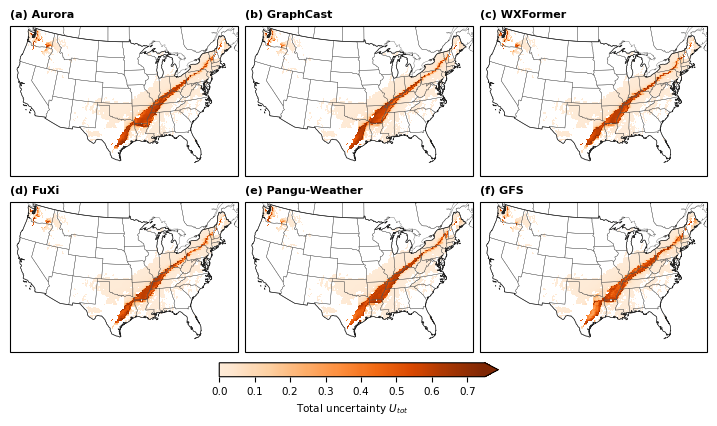

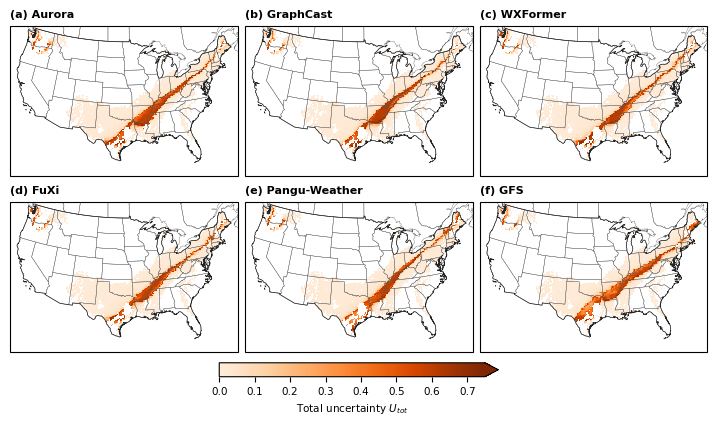

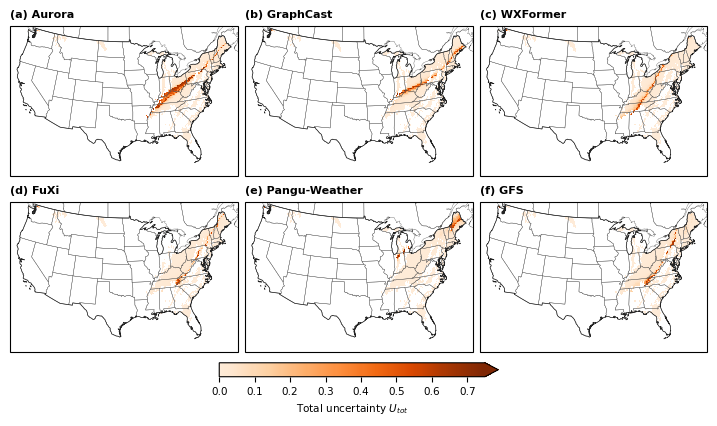

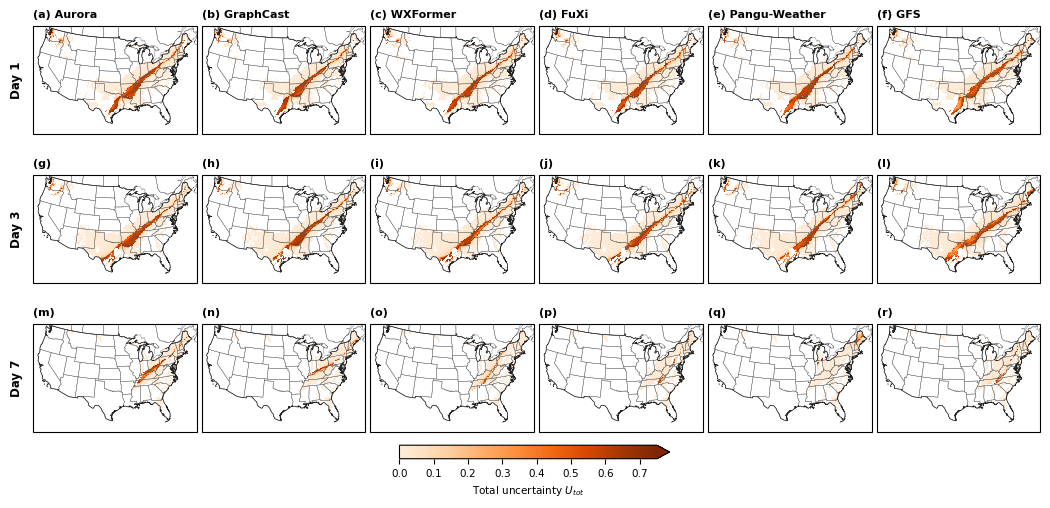

In [13]:
def setup_map(ax):
    ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())
    if DRAW_STATES:
        try:
            ax.add_feature(cfeature.STATES.with_scale("50m"), linewidth=0.25, edgecolor="#555555")
        except Exception as e:
            warnings.warn(f"state lines not drawn: {e}")
    ax.add_geometries([CONUS], crs=ccrs.PlateCarree(), facecolor="none",
                      edgecolor="#222222", linewidth=0.5)

def unc_panel(ax, field, title):
    setup_map(ax)
    im = ax.pcolormesh(LON_T, LAT_T, field, cmap=UNC_CMAP, vmin=0, vmax=UNC_VMAX,
                       shading="nearest", transform=ccrs.PlateCarree(), rasterized=True)
    if mixed is not None:
        for cls, (mk, col) in MIXED_STYLE.items():
            m = mixed[mixed.obs_class == cls]
            ax.scatter(m.lon, m.lat, s=6, marker=mk, facecolors="none", edgecolors=col,
                       linewidths=0.5, transform=ccrs.PlateCarree(), zorder=5)
    ax.set_title(title, loc="left", fontweight="bold")
    return im

def mixed_legend(fig, y):
    if mixed is None:
        return
    h = [Line2D([], [], ls="", marker=mk, mfc="none", mec=col, label=f"Obs. {cls}")
         for cls, (mk, col) in MIXED_STYLE.items()]
    fig.legend(handles=h, loc="lower center", ncol=2, frameon=False, fontsize=7, bbox_to_anchor=(0.5, y))

for day in UNC_DAYS:
    fig, axes = plt.subplots(2, 3, figsize=(9.0, 4.6), subplot_kw={"projection": PROJ},
                             gridspec_kw={"hspace": 0.15, "wspace": 0.03})
    for k, (ax, system) in enumerate(zip(axes.ravel(), EDNN_SYSTEMS)):
        im = unc_panel(ax, unc[(day, system)], f"({LETTERS[k]}) {system.replace(' — EDNN', '')}")
    cb = fig.colorbar(im, ax=axes, orientation="horizontal", fraction=0.04, pad=0.03,
                      shrink=0.4, extend="max")
    cb.set_label(r"Total uncertainty $U_{tot}$")
    mixed_legend(fig, -0.06)
    fig.savefig(FIG / f"case_study_total_uncertainty_{TIME_TAG}_day{day}.pdf", dpi=300, bbox_inches="tight")
    fig.savefig(FIG / f"case_study_total_uncertainty_{TIME_TAG}_day{day}.png", dpi=200, bbox_inches="tight")
    plt.show()

fig, axes = plt.subplots(len(UNC_DAYS), len(EDNN_SYSTEMS),
                         figsize=(13.0, 1.75 * len(UNC_DAYS) + 0.6),
                         subplot_kw={"projection": PROJ}, gridspec_kw={"hspace": 0.18, "wspace": 0.03})
axes = np.atleast_2d(axes)
k = 0
for r, day in enumerate(UNC_DAYS):
    for c, system in enumerate(EDNN_SYSTEMS):
        name = system.replace(" — EDNN", "")
        im = unc_panel(axes[r, c], unc[(day, system)], f"({LETTERS[k]}) {name}" if r == 0 else f"({LETTERS[k]})")
        k += 1
    axes[r, 0].text(-0.06, 0.5, f"Day {day}", transform=axes[r, 0].transAxes, rotation=90,
                    va="center", ha="right", fontsize=8.5, fontweight="bold")
cb = fig.colorbar(im, ax=axes, orientation="horizontal", fraction=0.03, pad=0.03,
                  shrink=0.35, extend="max")
cb.set_label(r"Total uncertainty $U_{tot}$")
mixed_legend(fig, -0.03)
fig.savefig(FIG / f"case_study_total_uncertainty_{TIME_TAG}_days.pdf", dpi=300, bbox_inches="tight")
plt.show()

## 8. Notes for the text

- The display area at each lead is the native GFS precipitation area **of that forecast**, so it differs between days. Compare patterns, not area totals, across days.
- The summary table describes the displayed area only. Uncertainty conditioned on the observed class (seasonal analysis, notebook 03) is the quantitative counterpart.
- Masking and regridding match notebook 05, so these maps can be read alongside the ptype and agreement figures.